# 3. Functions and Classes

Let us learn how to define your own *functions*, and further organize them into a *class* for neatness and extensibility.

**References**  
Python Tutorial (https://docs.python.org/3/tutorial/)
* Section 4.7-4.8: Functions
* Chapter 6: Modules
* Chapter 9: Classes

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Defining functions
If you find yourself running the same codes again and again with different inputs, it is time to define them as a *function*.

Here is a simple example:

In [2]:
def square(x):
    """Compute x*x"""
    # result returned
    return x*x

In [3]:
square(3)

9

In [4]:
a = np.array([1, 2, 3])
# input `x` can be anything for which `x*x` is valid
square(a)

array([1, 4, 9])

The line encosed by """ """ is called a *Docstring*, which is shown by `help( )` command.

In [5]:
help(square)

Help on function square in module __main__:

square(x)
    Compute x*x



In [30]:
square?

A function does not need to return anything.

In [8]:
def print_square(x):
    """Print x*x"""
    print(x*x)
# the end of indentation is the end of definition
print_square(a)

[1 4 9]


A function can return multiple values.

In [9]:
def square_cube(x):
    """Compute x**2 and x**3"""
    # return multiple values separated by comma
    return x**2, x**3
# results can be assigned to variables separated by comma
b, c = square_cube(a)
print(b, c)

[1 4 9] [ 1  8 27]


In [10]:
square_cube(3)

(9, 27)

### Arguments and local variables
A function can take single, multiple, or no arguments (inputs).  
An argument can be required, or optional with a default value.  
An argument can be specified by the position, or a keyword.

In [11]:
def norm(x, p=2):
    """Give the L^p norm of a vector."""
    y = abs(x) ** p
    return np.sum(y) ** (1/p)

In [12]:
a = np.array([1, 2, -2])
norm(a)  # default p=2

np.float64(3.0)

In [13]:
norm(a, 1)  # specify by position

np.float64(5.0)

In [14]:
norm(p=1, x=a)  # specify by the keywords, in any oder

np.float64(5.0)

### Local and global variables
Arguments and variables assigned in a function are registered in a local *namespace*.

In [15]:
y = 0  # global variable
norm(a)  # this uses `y` as local variable, y=[1, 4, 9]
print(y)  # the global variable `y` is not affected

0


Any *global* variables can be referenced within a function.

In [16]:
a = 1  # global variable
def add_a(x):
    """Add x and a."""
    return a + x
print(add_a(1))  # 1 + 1
a = 2
print(add_a(1))  # 1 + 2

2
3


To modify a global variable from inside a function, it have to be declaired as `global`.

In [17]:
a = 1
def addto_a(x):
    """Add x into a."""
    global a
    a = a + x  # add x to a
addto_a(1)  # a = a + 1
print(a)
addto_a(1)  # a = a + 1
print(a)

2
3


You can modify an argument in a function.

In [18]:
def double(x):
    """Double x"""
    x = 2 * x
    return x
double(1)

2

## Script
Before Jupyter (iPython) notebook was created, to reuse any code, you had to store it in a text file, with `.py` extension by convention. This is called a *script*.

This magic command creates a simple script file.

In [19]:
%%file hello.py
print('Hello!')

Writing hello.py


In [20]:
%cat hello.py

print('Hello!')


The standard way of running a script is to type in a terminal:
```
$ python hello.py
```
In a Jupyter notebook, you can use `%run` magic command.

In [21]:
%run hello.py

Hello!


You can edit a python script by any text editor.

In Jupyter notebook's `Files` window, you can make a new script as a Text file by `New` menu, or edit an existing script by clicking the file name.

### Module
A script with function definitions is called a *module*.  

In [22]:
%%file lpnorm.py
"""L^p norm module"""

import numpy as np

def norm(x, p=2):
    """The L^p norm of a vector."""
    y = abs(x) ** p
    return np.sum(y) ** (1/p)

def normalize(x, p=2):
    """L^p normalization"""
    return x/norm(x, p)

Writing lpnorm.py


In [23]:
%cat lpnorm.py

"""L^p norm module"""

import numpy as np

def norm(x, p=2):
    """The L^p norm of a vector."""
    y = abs(x) ** p
    return np.sum(y) ** (1/p)

def normalize(x, p=2):
    """L^p normalization"""
    return x/norm(x, p)


You can import a module and use its function by `module.function()`.

In [24]:
import lpnorm

In [25]:
help(lpnorm)

Help on module lpnorm:

NAME
    lpnorm - L^p norm module

FUNCTIONS
    norm(x, p=2)
        The L^p norm of a vector.

    normalize(x, p=2)
        L^p normalization

FILE
    /content/lpnorm.py




In [29]:
lpnorm?

In [26]:
a = np.array([-3, 4])
lpnorm.norm(a)

np.float64(5.0)

In [27]:
lpnorm.norm(a,1)

np.float64(7.0)

In [28]:
lpnorm.normalize(a)

array([-0.6,  0.8])

Caution: Python reads in a module only upon the first `import`, as popular modules like `numpy` are imported in many modules. If you modify your module, you need to restart your kernel or call `importlib.reload()`.

In [ ]:
import importlib
importlib.reload(lpnorm)

### Package
A collection of modules are put in a directory as a *package*.  

In [31]:
# see how numpy is organized
%ls $CONDA_PREFIX/lib/python*/site-packages/numpy

ls: cannot access '/lib/python*/site-packages/numpy': No such file or directory


## Object Oriented Programming
Object Oriented Programming has been advocated since 1980's in order to avoid naming conflicts and to allow incremental software development by promoting modularity.

Examples are: SmallTalk, Objective C, C++, Java,... and Python!  

Major features of OOP is:
* define data structure and functions together as a *Class*
* an *instance* of a class is created as an *object*
* the data (attributes) and functions (methods) are referenced as `instance.attribute` and `instance.method()`.
* a new class can be created as a *subclass* of existing classes to inherit their attributes and methods.

## Defining a basic class
Definition of a class starts with  
```class ClassName(BaseClass):```  
and include
* any definition of attributes
* `__init__()` method called when a new instance is created
* definition of other methods

The first argument of a method specifies the instance, which is named `self` by convention.

Here's a simple class for describing cells in 2D space.

In [32]:
class Cell:
    """Class for a cell"""

    def __init__(self, position = [0,0], radius=0.1, color=[1,0,0,0.5]):
        """Make a new cell"""
        self.position = np.array(position)
        self.radius = radius
        self.color = color

    def show(self):
        """Visualize as a circule"""
        c = plt.Circle(self.position,self.radius,color=self.color)
        plt.gca().add_patch(c)
        plt.axis('equal')

Let's create an instance of a class by calling like a function.

In [33]:
cell = Cell()

Attributes and methods are referenced by `.`

In [34]:
cell.position

array([0, 0])

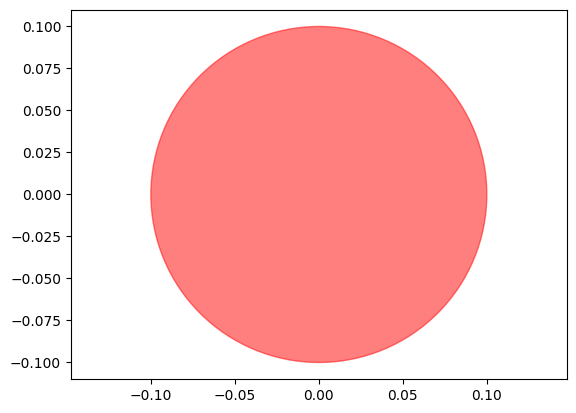

In [35]:
cell.show()

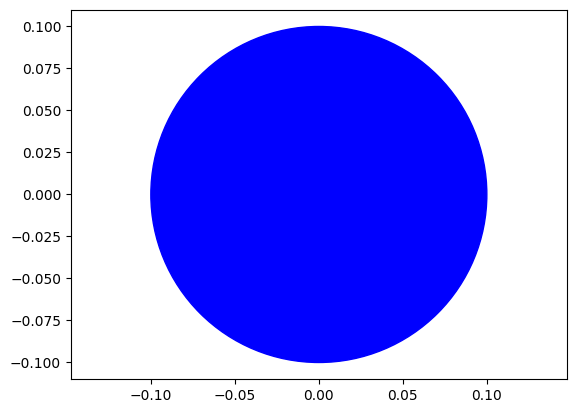

In [36]:
cell.color = 'b'
cell.show()

You can create an array of class instances.

In [37]:
n = 10
cells = [Cell(np.random.rand(2),color=np.random.rand(4)) for i in range(n)]

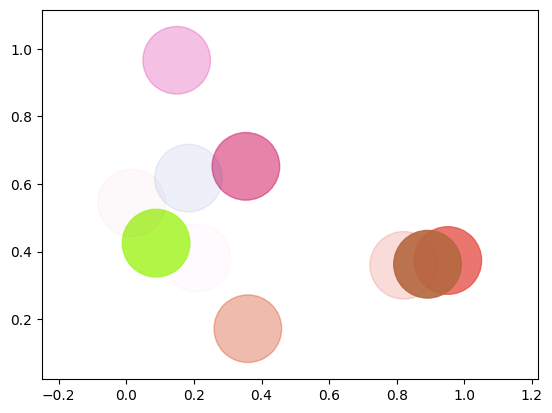

In [38]:
for i in range(n):
    cells[i].show()

A subclass can inherit attributes and methods of base class.

In [39]:
class gCell(Cell):
    """Class of growing cell based on Cell class"""

    def grow(self, scale=2):
        """Grow the area of the cell"""
        self.radius *= np.sqrt(scale)

    def duplicate(self):
        """Make a copy with a random shift"""
        c = gCell(self.position+np.random.randn(2)*self.radius, self.radius, self.color)
        return c

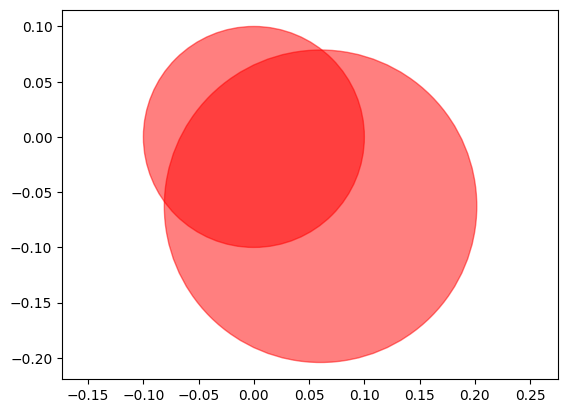

In [40]:
c0 = gCell()
c0.show()
c1 = c0.duplicate()
c1.grow()
c1.show()

Let us make a new class using gCell class

In [41]:
class Culture():
    """Class for a cell culture"""

    def __init__(self, n=10, position=None, radius=0.1, color=None):
        """Make a cell culture with n cells"""
        self.number = n  # nuber of cells
        if position == None:  # random position if not specified
            position = np.random.rand(n,2)
        if color == None:  # random colors if not specified
            color = np.random.rand(n,4)
        self.cells = [gCell(position[i],radius=radius,color=color[i]) for i in range(n)]

    def show(self):
        """Visualize as a circules"""
        for i in range(self.number):
            self.cells[i].show()

    def grow(self, scale=2):
        """Grow the area of each cell"""
        for i in range(self.number):
            self.cells[i].grow(scale)

    def duplicate(self):
        """Make a copy of each cell"""
        for i in range(self.number):
            c = self.cells[i].duplicate()
            self.cells.append(c)
        self.number *= 2

In [42]:
culture = Culture()

In [43]:
culture.cells[0].position

array([0.65188895, 0.31146962])

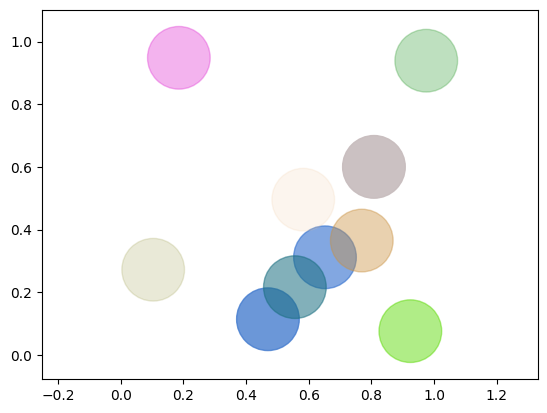

In [44]:
culture.show()

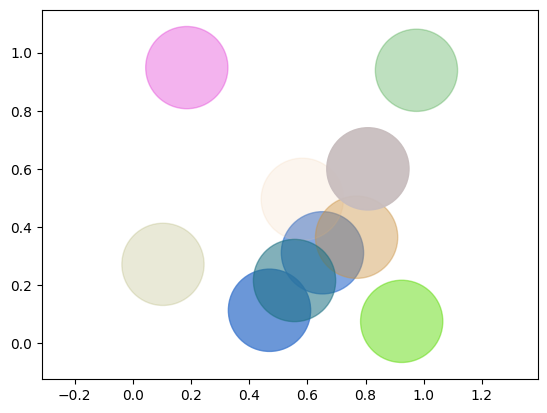

In [45]:
culture.grow()
culture.show()

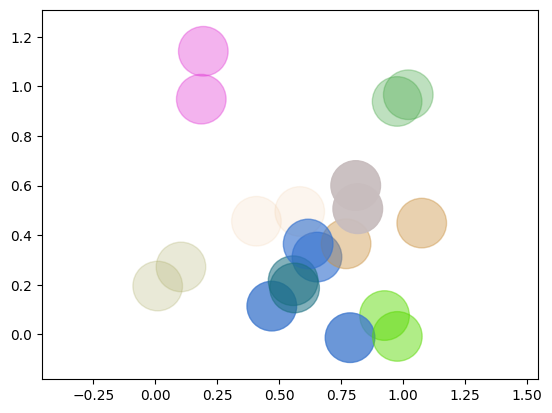

In [46]:
culture.duplicate()
culture.grow(0.5)
culture.show()